In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
dataseed = pd.read_csv("seed.xls",sep=";")
dataseed

,area,perimeter,compactness,length,width,coefficient,groove,class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1
...,...,...,...,...,...,...,...,...
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3


In [3]:
dataseed.columns

Index(['area', 'perimeter', 'compactness', 'length', 'width', 'coefficient',
       'groove', 'class'],
      dtype='object')

In [4]:
x = dataseed.drop('class',axis = 1)
y = dataseed['class']

In [5]:
x

,area,perimeter,compactness,length,width,coefficient,groove
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175
...,...,...,...,...,...,...,...
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044


In [6]:
y

0      1
1      1
2      1
3      1
4      1
      ..
205    3
206    3
207    3
208    3
209    3
Name: class, Length: 210, dtype: int64

In [7]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.25, random_state = 0)

In [8]:
!pip uninstall scikit-learn scipy numpy -y
!pip install numpy scipy scikit-learn

Found existing installation: scikit-learn 1.3.2
Uninstalling scikit-learn-1.3.2:
  Successfully uninstalled scikit-learn-1.3.2


ERROR: Exception:
Traceback (most recent call last):
  File "C:\Users\LENOVO\anaconda3\lib\site-packages\pip\_internal\cli\base_command.py", line 189, in _main
    status = self.run(options, args)
  File "C:\Users\LENOVO\anaconda3\lib\site-packages\pip\_internal\commands\uninstall.py", line 91, in run
    uninstall_pathset.commit()
  File "C:\Users\LENOVO\anaconda3\lib\site-packages\pip\_internal\req\req_uninstall.py", line 456, in commit
    self._moved_paths.commit()
  File "C:\Users\LENOVO\anaconda3\lib\site-packages\pip\_internal\req\req_uninstall.py", line 296, in commit
    save_dir.cleanup()
  File "C:\Users\LENOVO\anaconda3\lib\site-packages\pip\_internal\utils\temp_dir.py", line 205, in cleanup
    rmtree(ensure_text(self._path))
  File "C:\Users\LENOVO\anaconda3\lib\site-packages\pip\_vendor\retrying.py", line 49, in wrapped_f
    return Retrying(*dargs, **dkw).call(f, *args, **kw)
  File "C:\Users\LENOVO\anaconda3\lib\site-packages\pip\_vendor\retrying.py", line 212, in call

  Using cached scikit_learn-1.3.2-cp38-cp38-win_amd64.whl (9.3 MB)


In [9]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(x_train, y_train)

KNeighborsClassifier(n_neighbors=7)

In [10]:
y_pred= knn.predict(x_test)

In [11]:
x_new = np.array([[15,25.5,7,30,11,5,10]])
prediksi = knn.predict(x_new)
print(prediksi)

[2]


C:\Users\LENOVO\anaconda3\lib\site-packages\sklearn\base.py:465: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [12]:
from sklearn.metrics import accuracy_score

akurasi = accuracy_score(y_test, y_pred)
print(akurasi)

0.8867924528301887


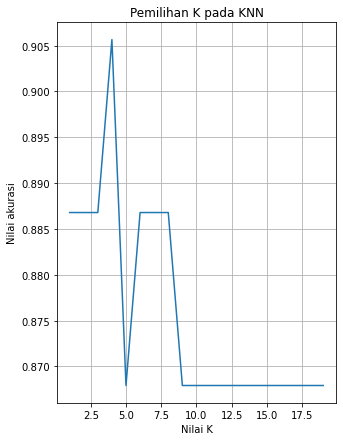

In [13]:
k_values = range(1, 20)
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors = k)
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
    
plt.figure(figsize = (5, 7))
plt.plot(k_values, accuracies)
plt.xlabel("Nilai K")
plt.ylabel("Nilai akurasi")
plt.title("Pemilihan K pada KNN")
plt.grid(True)
plt.show()